# 01 数据质量诊断与清洗效果评估

**组织**：迪庆清风青年公益联合会（云南省迪庆藏族自治州）
**分析对象**：多源运营台账（项目 / 志愿者 / 签到 / 捐赠 / 物资 / 预算 / 问卷）
**数据性质**：模拟数据，但**故意按真实场景注入了七类脏数据**，并留下了一份不对外公开的"缺陷真值表"，因此清洗效果可以被客观打分。

---

## 本 notebook 要回答的业务问题

1. 原始台账到底"脏"在哪里？缺陷在哪些表、哪些字段上聚集，属于什么性质的事故？
2. 清洗流水线声称的每一次修复，是否真的在数据里生效了？有没有"日志写了但其实没修"的假修复？
3. 清洗之后还剩哪些空值与异常？它们会不会污染指标体系的口径？
4. 独立的规则校验（`qingfeng.validate`）与清洗日志能互相印证吗？哪些问题必须回到源头补录，而不是再写清洗规则？

## 数据来源说明

| 数据 | 路径 | 说明 |
| --- | --- | --- |
| 原始台账（含注入缺陷） | `data/raw/*.csv` | `utf-8-sig` 编码，模拟多源系统导出 |
| 缺陷真值表 | `data/raw/_ground_truth/injected_defects.csv` | 逐单元格记录注入的缺陷类型与位置 |
| 清洗日志 | `data/processed/cleaning_log.csv` | 每一步清洗动作、影响行数与备注 |
| 清洗结果 | `data/interim/*_clean.csv` | 清洗后回写给中间层 |
| 星型模型 | `data/processed/dim_*.csv` / `fact_*.csv` | 分析层直接消费的表 |

> 方法论说明：本 notebook 用**不变量（invariant）**而不是"看起来干净"来评价清洗。
> 每一类缺陷都对应一条可用代码判定的不变量（例如"业务主键唯一""日期全部为 ISO 格式"），
> 只有当注入缺陷全部被消除、不变量零残留时，才认定清洗有效。

## 结论摘要

- **缺陷是有结构的，不是随机噪声**：空白/全角字符与关键字段缺失是数量最大的两类；重复导入高度集中在签到、服务、捐赠三张流水表，是典型的批量重复导入事故；单位混用只出现在"时长"和"数量"两个数值列上。
- **清洗有效性可以证明**：对六类可机械判定、且不涉及"信息补全"的缺陷（重复行、日期格式、空白/全角、单位混用、极端离群值、外键悬空），清洗后残留**全部为零**，不变量成立。
- **缺失值不是"一类处理"**：清洗日志实际执行了多种互相不同的合同——维度回填 UNKNOWN 占位、剔除整行、跨表反推、星型模型 UNKNOWN 兜底、分析口径显式排除、按设计保留为空。逐条与数据核对后，所有声明已处理的字段残留为零，唯一的保留为空项也与日志中"无法反推"的登记行数完全一致。
- **残余风险的性质变了**：剩下的空值不再是"数据错误"，而是"业务信息本身缺失"（可选描述字段，以及个别源头档案残缺）。它们不破坏结构性不变量，但会让少数维度汇总少计记录，只能靠源头补录解决。
- **对下游的影响有限且已量化**：关键度量的空值全部落在分析口径显式排除的范围内；真正需要跟进的是少量的档案残缺，本 notebook 给出了逐字段的缺失率与影响面。

In [1]:
%matplotlib inline
import logging
import re
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from qingfeng.config import load_config
from qingfeng.pipeline import load_artifacts, load_cleaning_log
from qingfeng.viz import setup_style

warnings.filterwarnings("ignore")
logging.getLogger("qingfeng").setLevel(logging.WARNING)   # 管道内部 INFO 日志不进入 notebook 输出
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)

cfg = load_config()                      # 所有路径均已解析为绝对路径
arts = load_artifacts(cfg)               # 复用管道产物，避免重复计算
star = arts["star"]
cleaned = arts["cleaned"]
log = load_cleaning_log(cfg)
FIG = cfg.paths.figures
setup_style(cfg)                         # 复用管道的中文字体与配色，保证图文风格一致

print(f"分析对象：{cfg.org_name}（{cfg.region}）")
print(f"数据窗口：{cfg.simulation.start_date} ~ {cfg.simulation.as_of_date}")
print(f"随机种子：{cfg.simulation.seed}（数据完全可复现）")


def show(fig, name: str, caption: str = ""):
    # 落盘并内嵌显示自绘图表，保证图表数据被写进 .ipynb 输出
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))
    if caption:
        print(caption)
    print(f"（本 notebook 自绘图表已保存：{path.relative_to(cfg.paths.root)}）")


def pipeline_figure(name: str, caption: str = ""):
    # 直接引用管道已产出的图表
    path = FIG / name
    display(Image(filename=str(path)))
    if caption:
        print(caption)
    

# ---- 原始台账与清洗结果的对账基线 -----------------------------------------
TABLES = [
    "beneficiaries", "beneficiary_services", "donations", "donors", "in_kind_donations",
    "monthly_budget_execution", "projects", "satisfaction_survey_raw", "staff",
    "volunteer_shifts", "volunteers",
]
raw = {name: pd.read_csv(cfg.paths.raw_file(f"{name}.csv"), encoding="utf-8-sig", low_memory=False)
       for name in TABLES}
truth = pd.read_csv(cfg.paths.raw / "_ground_truth" / "injected_defects.csv", encoding="utf-8-sig")

inventory = pd.DataFrame(
    {
        "表": TABLES,
        "原始行数": [len(raw[t]) for t in TABLES],
        "清洗后行数": [len(cleaned[t]) for t in TABLES],
        "原始字段数": [raw[t].shape[1] for t in TABLES],
    }
)
inventory["剔除行数"] = inventory["原始行数"] - inventory["清洗后行数"]
inventory["保留率"] = (inventory["清洗后行数"] / inventory["原始行数"]).round(4)
display(inventory.sort_values("原始行数", ascending=False).reset_index(drop=True))
print(f"台账合计：原始 {inventory['原始行数'].sum():,} 行 → 清洗后 {inventory['清洗后行数'].sum():,} 行；"
      f"缺陷真值表共登记 {len(truth):,} 个注入单元格，覆盖 {truth['table'].nunique()} 张表 / {truth['defect_type'].nunique()} 类缺陷")

分析对象：迪庆清风青年公益联合会（云南省迪庆藏族自治州）
数据窗口：2024-01-01 ~ 2026-06-30
随机种子：20260601（数据完全可复现）


,表,原始行数,清洗后行数,原始字段数,剔除行数,保留率
0,donations,21370,19988,8,1382,0.9353
1,beneficiary_services,17181,16137,10,1044,0.9392
2,volunteer_shifts,13492,12888,8,604,0.9552
3,beneficiaries,5434,5140,11,294,0.9459
4,donors,5434,5200,7,234,0.9569
5,monthly_budget_execution,3994,3762,5,232,0.9419
6,volunteers,3762,3600,13,162,0.9569
7,satisfaction_survey_raw,1515,1450,11,65,0.9571
8,in_kind_donations,648,612,11,36,0.9444
9,projects,54,52,16,2,0.9630


台账合计：原始 72,898 行 → 清洗后 68,843 行；缺陷真值表共登记 23,361 个注入单元格，覆盖 10 张表 / 7 类缺陷


## 1. 缺陷注入清单：我们面对的到底是什么问题

先看清"敌人"。真值表逐单元格记录了注入位置，按缺陷类型与表交叉后，
可以判断每一类缺陷是**单点录入错误**（如某行日期写成 `2024/3/5`）还是**系统性事故**（如整表重复导入）。
这个区别决定了清洗策略：单点错误可以逐格修，系统性事故必须按业务键去重。

,注入条数,涉及表数,涉及字段数,占全部缺陷
缺陷类型,,,,
空白/全角字符,8005,10,11,0.3427
关键字段缺失,6277,10,46,0.2687
日期格式错乱,3587,9,9,0.1535
重复行（重复导入）,3138,10,1,0.1343
极端离群值,1008,8,9,0.0431
单位混用,947,2,2,0.0405
外键悬空,399,3,3,0.0171


缺陷类型 × 表 的分布（行=缺陷类型，列=表，格=注入单元格数）


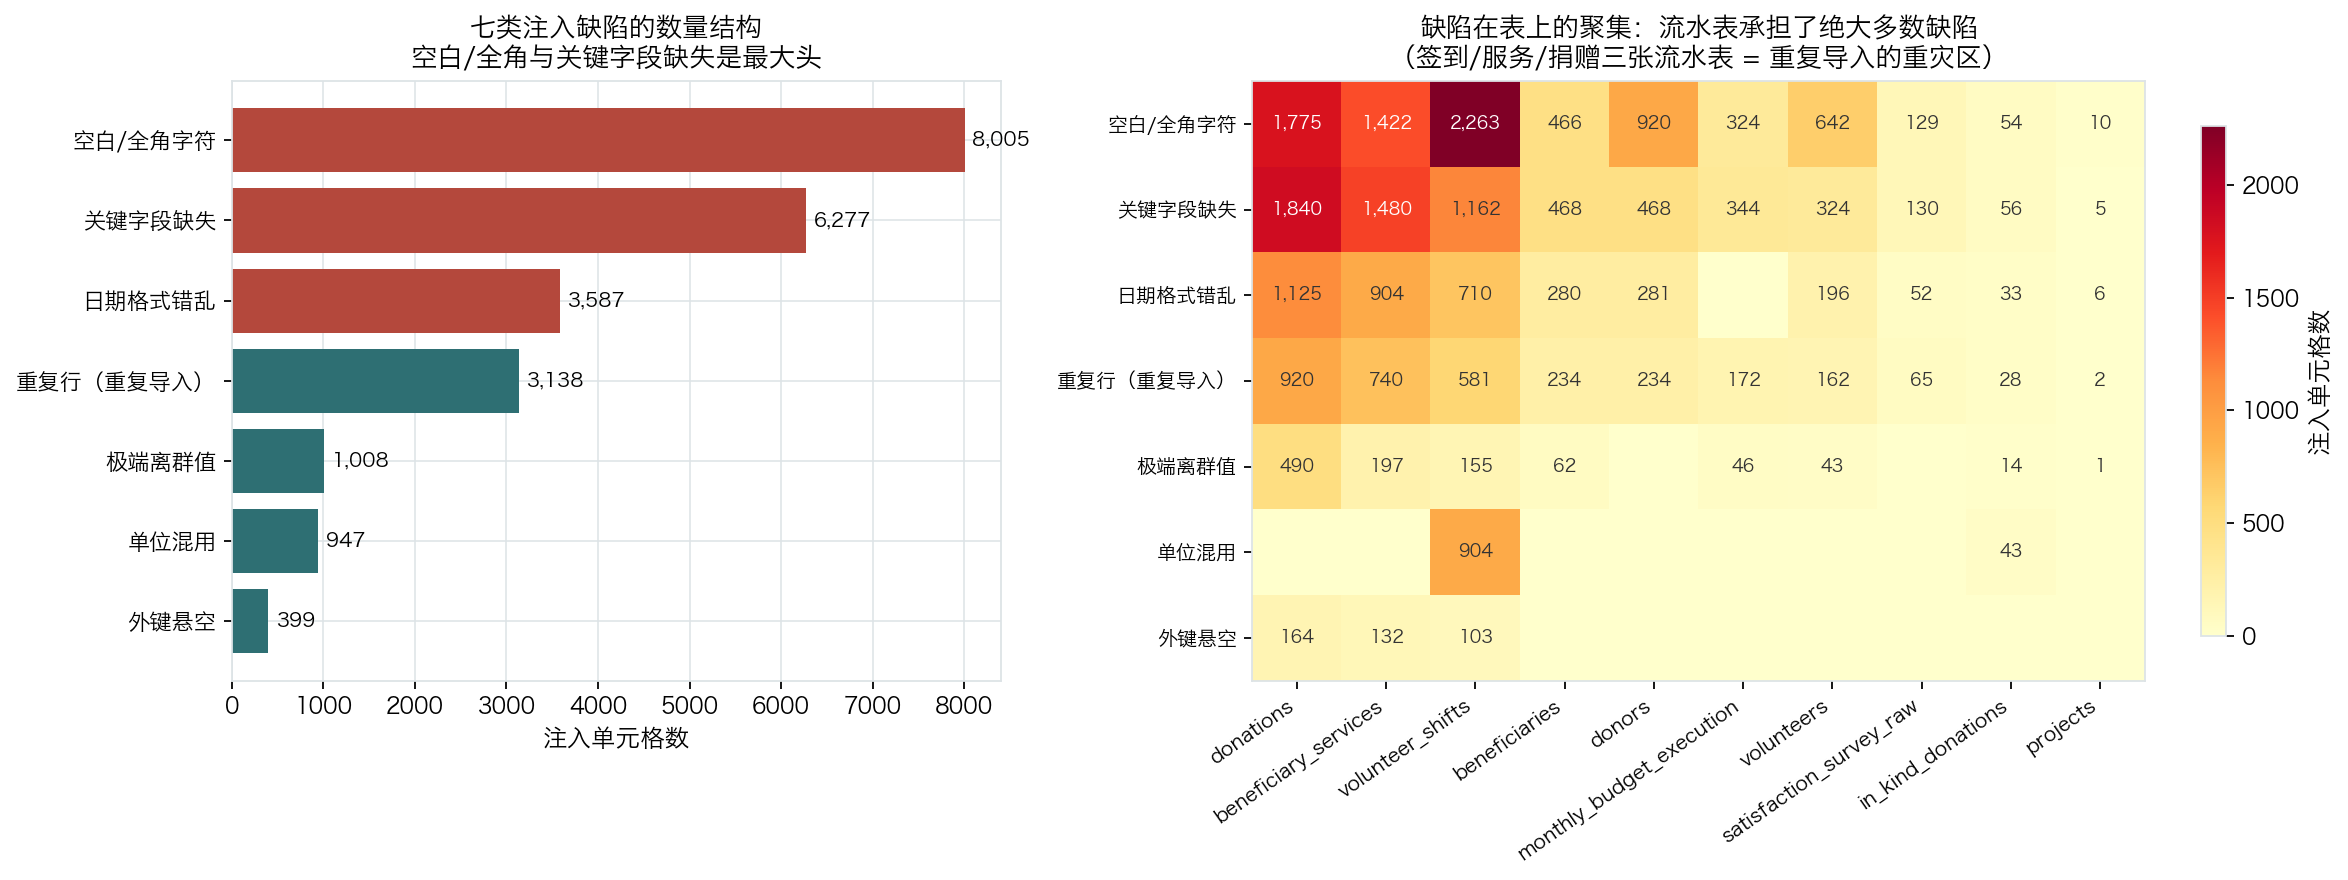

注：空白/全角字符 一类就占全部注入缺陷的 34.3%，而重复行在 10 张表上出现，其中流水表占绝大多数。
（本 notebook 自绘图表已保存：reports/figures/nb01_injected_defects.png）


,重复行注入数
table,
donations,920
beneficiary_services,740
volunteer_shifts,581
beneficiaries,234
donors,234
monthly_budget_execution,172
volunteers,162
satisfaction_survey_raw,65
in_kind_donations,28


In [2]:
DEFECT_LABELS = {
    "duplicate_row": "重复行（重复导入）",
    "missing_value": "关键字段缺失",
    "malformed_date": "日期格式错乱",
    "unit_inconsistency": "单位混用",
    "extreme_outlier": "极端离群值",
    "orphan_foreign_key": "外键悬空",
    "whitespace_or_widechar": "空白/全角字符",
    # 以下为清洗层额外发现、未在缺陷真值表中出现的质量问题（自由文本/派生字段等）
    "nonstandard_code": "非标准编码（自由文本）",
    "inconsistent_derived": "派生字段不一致（单价×数量）",
    "out_of_range": "数值越界",
    "future_date": "未来日期",
    "statistical_outlier": "统计离群点（仅标记）",
    "unknown_unit": "未知单位（保留待确认）",
    "date_unparseable": "日期无法解析",
}
truth["缺陷类型"] = truth["defect_type"].map(DEFECT_LABELS)

by_type = (truth.groupby("缺陷类型")
           .agg(注入条数=("defect_type", "size"), 涉及表数=("table", "nunique"),
                涉及字段数=("column", "nunique"))
           .sort_values("注入条数", ascending=False))
by_type["占全部缺陷"] = (by_type["注入条数"] / by_type["注入条数"].sum()).round(4)
display(by_type)

cross = (truth.pivot_table(index="缺陷类型", columns="table", values="column",
                           aggfunc="size", fill_value=0)
         .reindex(by_type.index))
cross = cross[[c for c in inventory.sort_values("原始行数", ascending=False)["表"] if c in cross.columns]]
print("缺陷类型 × 表 的分布（行=缺陷类型，列=表，格=注入单元格数）")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 1.45]})
ax = axes[0]
colors = [cfg.color("danger") if v > by_type["注入条数"].median() else cfg.color("primary")
          for v in by_type["注入条数"]]
ax.barh(by_type.index[::-1], by_type["注入条数"].to_numpy()[::-1], color=colors[::-1])
for y, v in enumerate(by_type["注入条数"].to_numpy()[::-1]):
    ax.text(v + by_type["注入条数"].max() * 0.01, y, f"{v:,}", va="center", fontsize=9)
ax.set_xlabel("注入单元格数")
ax.set_title("七类注入缺陷的数量结构\n空白/全角与关键字段缺失是最大头", fontsize=12)

ax = axes[1]
im = ax.imshow(cross.to_numpy(), aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(cross.shape[1]), cross.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(cross.shape[0]), cross.index, fontsize=9)
vmax = cross.to_numpy().max()
for i in range(cross.shape[0]):
    for j in range(cross.shape[1]):
        v = cross.iloc[i, j]
        if v:
            ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8,
                    color="white" if v > vmax * 0.6 else "#333333")
ax.set_title("缺陷在表上的聚集：流水表承担了绝大多数缺陷\n（签到/服务/捐赠三张流水表 = 重复导入的重灾区）", fontsize=12)
ax.grid(False)
fig.colorbar(im, ax=ax, label="注入单元格数", shrink=0.85)
fig.tight_layout()
show(fig, "nb01_injected_defects",
     f"注：{by_type.index[0]} 一类就占全部注入缺陷的 {by_type['占全部缺陷'].iloc[0]:.1%}，"
     f"而重复行在 {cross.loc['重复行（重复导入）'].gt(0).sum()} 张表上出现，其中流水表占绝大多数。")

concentration = cross.loc[["重复行（重复导入）"]].T
concentration.columns = ["重复行注入数"]
display(concentration[concentration["重复行注入数"] > 0].sort_values("重复行注入数", ascending=False))

**怎么读这张图**：左下角的数量结构告诉我们"最该先修什么"，右侧热力图告诉我们"哪些表最不可信"。

- 空白/全角字符是**纯格式问题**：它不影响数值口径，但会让 `"德钦县 "` 与 `"德钦县"` 被当成两个县，直接造成维度分裂——这是最容易被忽视、危害却最隐蔽的一类。
- 关键字段缺失同时出现在维度表和度量列上，处理方式必须区分：**维度字段可以回填 UNKNOWN 保留记录，度量字段缺失则无法参与汇总，只能剔除整行**。
- 重复行高度集中在签到、服务、捐赠三张流水表，这是"纸质台账补录 + 批量导入"的典型特征。对这类事故，按业务组合键（对象+项目+日期+服务类型）去重比按全字段去重更可靠，因为重复导入的两行可能在个别字段上有细微差异。
- 单位混用只出现在 `volunteer_shifts.hours` 与 `in_kind_donations.quantity`：这两列的人为录入自由度最高（"3h"/"180min"/"3"），是口径最脆弱的地方。

> 业务含义：缺陷集中在**记录质量**而非**业务逻辑**上，说明问题出在录入与接入环节。
> 修复方案应当一半在清洗层（去重、归一化），一半在源头（表单校验、导入模板）。

## 2. 清洗前后记录量对账

清洗必须"可对账"：每一行被丢弃都要有日志解释。下面把原始行数与清洗后行数并列，
并算出保留率——保留率异常低的表，要么确实脏，要么清洗规则过激，两种都值得追问。

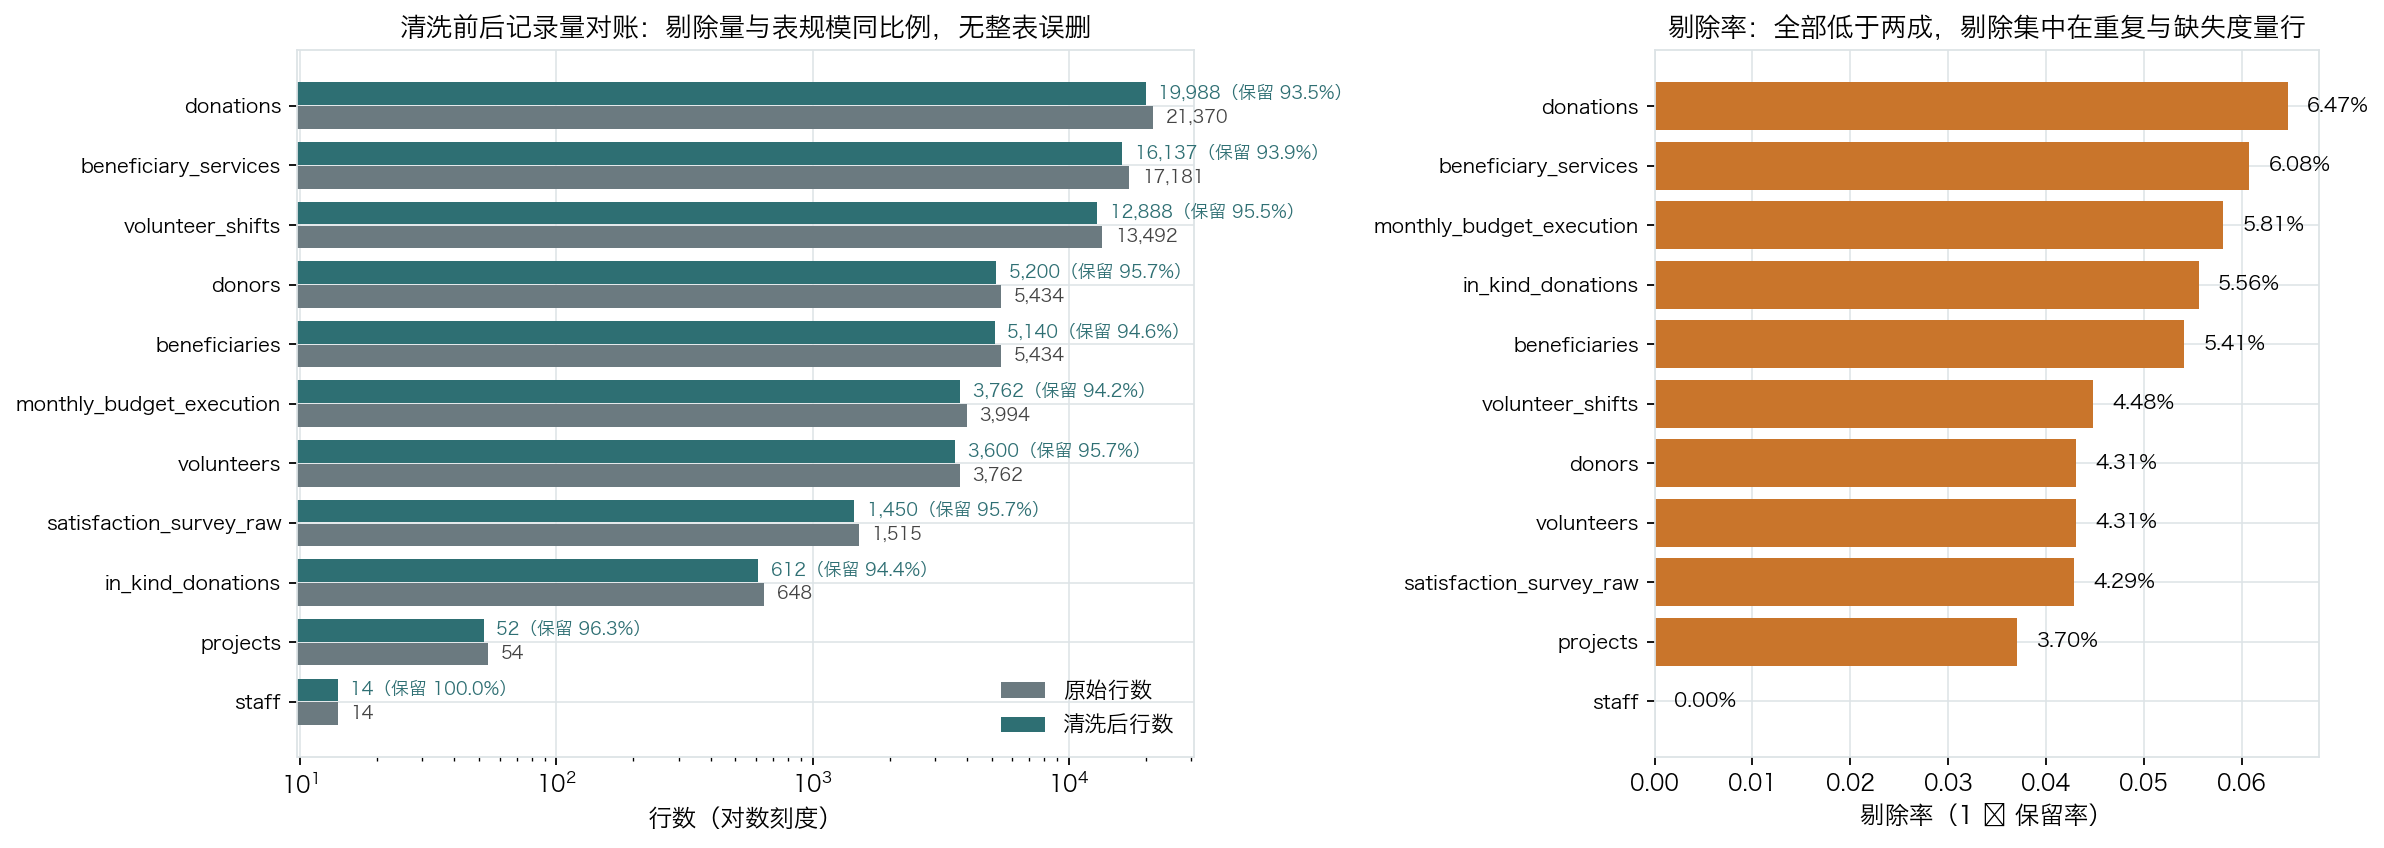

总保留率 94.44%；剔除率最高的是 donations（6.47%），最低的是 staff（0.00%）。
（本 notebook 自绘图表已保存：reports/figures/nb01_raw_vs_cleaned.png）


,表,原始行数,清洗后行数,剔除行数,剔除率
0,donations,21370,19988,1382,0.0647
1,beneficiary_services,17181,16137,1044,0.0608
2,monthly_budget_execution,3994,3762,232,0.0581
3,in_kind_donations,648,612,36,0.0556
4,beneficiaries,5434,5140,294,0.0541
5,volunteer_shifts,13492,12888,604,0.0448
6,donors,5434,5200,234,0.0431
7,volunteers,3762,3600,162,0.0431
8,satisfaction_survey_raw,1515,1450,65,0.0429
9,projects,54,52,2,0.0370


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.35, 1]})
order = inventory.sort_values("原始行数", ascending=True)
y = np.arange(len(order))
ax = axes[0]
ax.barh(y - 0.2, order["原始行数"], height=0.38, color=cfg.color("neutral"), label="原始行数")
ax.barh(y + 0.2, order["清洗后行数"], height=0.38, color=cfg.color("primary"), label="清洗后行数")
ax.set_yticks(y, order["表"], fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("行数（对数刻度）")
ax.set_title("清洗前后记录量对账：剔除量与表规模同比例，无整表误删", fontsize=12)
for yy, (raw_n, clean_n, keep) in enumerate(zip(order["原始行数"], order["清洗后行数"], order["保留率"])):
    ax.text(raw_n * 1.12, yy - 0.2, f"{raw_n:,}", va="center", fontsize=8, color="#444444")
    ax.text(clean_n * 1.12, yy + 0.2, f"{clean_n:,}（保留 {keep:.1%}）", va="center", fontsize=8,
            color=cfg.color("primary"))
ax.legend(loc="lower right")

ax = axes[1]
drop = order.assign(剔除率=1 - order["保留率"]).sort_values("剔除率")
ax.barh(drop["表"], drop["剔除率"], color=cfg.color("secondary"))
for yy, v in enumerate(drop["剔除率"]):
    ax.text(v + 0.002, yy, f"{v:.2%}", va="center", fontsize=9)
ax.set_xlabel("剔除率（1 − 保留率）")
ax.set_title("剔除率：全部低于两成，剔除集中在重复与缺失度量行", fontsize=12)
ax.tick_params(axis="y", labelsize=9)
fig.tight_layout()
show(fig, "nb01_raw_vs_cleaned",
     f"总保留率 {inventory['清洗后行数'].sum() / inventory['原始行数'].sum():.2%}；"
     f"剔除率最高的是 {drop['表'].iloc[-1]}（{drop['剔除率'].iloc[-1]:.2%}），最低的是 {drop['表'].iloc[0]}（{drop['剔除率'].iloc[0]:.2%}）。")

display(inventory.assign(剔除率=(1 - inventory["保留率"]).round(4))
        .sort_values("剔除率", ascending=False)[["表", "原始行数", "清洗后行数", "剔除行数", "剔除率"]]
        .reset_index(drop=True))

**怎么对账**：所有表的保留率都保持在较高水平，说明清洗是"定点修复"而不是"大范围删数据"。
真正需要解释的是**剔除最多的那几张表**：剔除来源只有两类——重复行（导入事故）与关键度量缺失（无法参与汇总）。
下面用清洗日志验证这个判断。

## 3. 清洗动作清单：日志说了什么

清洗日志是审计线索。把日志按"问题类型 × 动作"聚合，可以立刻看出清洗层覆盖了哪些问题、
以及每个动作的影响面有多大。这里同时回答一个关键问题：**日志动作与真值表缺陷类型是否一一对应**——
如果真值表里有某类缺陷，日志里却完全没有对应动作，那就是漏清洗。

In [4]:
log["issue"] = log["issue"].map(lambda s: DEFECT_LABELS.get(s, s))
by_issue = (log.groupby("issue")
            .agg(动作条数=("action", "nunique"), 影响行数=("affected_rows", "sum"),
                 涉及表数=("table", "nunique"))
            .sort_values("影响行数", ascending=False))
by_issue["占全部清洗行数"] = (by_issue["影响行数"] / by_issue["影响行数"].sum()).round(4)
display(by_issue)

print("\n清洗动作影响面 Top 12（同一动作可能跨多表，这里按动作聚合）")
top_actions = (log.groupby("action")
               .agg(影响行数=("affected_rows", "sum"), 涉及表数=("table", "nunique"),
                    涉及字段数=("column", "nunique"))
               .sort_values("影响行数", ascending=False).head(12))
display(top_actions)
print(f"清洗日志共 {len(log)} 条动作、{log['table'].nunique()} 张表，累计影响 {log['affected_rows'].sum():,} 行"
      f"（同一行可能被多个动作处理，因此该数大于表行数）")

truth_types = set(truth["缺陷类型"])
log_types = set(log["issue"])
print(f"\n真值表中的缺陷类型：{sorted(truth_types)}")
print(f"日志中出现的处理类型：{sorted(log_types)}")
print(f"真值表有、日志无对应动作的类型：{sorted(truth_types - log_types - {'关键字段缺失'}) or '无（缺失值单列在 §5 处理）'}")

,动作条数,影响行数,涉及表数,占全部清洗行数
issue,,,,
日期格式错乱,1,68802,10,0.7144
关键字段缺失,8,10952,8,0.1137
空白/全角字符,1,10132,10,0.1052
重复行（重复导入）,3,3496,10,0.0363
极端离群值,8,1019,8,0.0106
单位混用,2,942,2,0.0098
外键悬空,1,572,3,0.0059
非标准编码（自由文本）,4,386,1,0.0040
派生字段不一致（单价×数量）,1,13,1,0.0001



清洗动作影响面 Top 12（同一动作可能跨多表，这里按动作聚合）


,影响行数,涉及表数,涉及字段数
action,,,
统一为 ISO 日期（多格式解析）,68802,10,11
去除空白/全角转半角,10132,10,13
非定向捐赠归入 UNKNOWN（机构统筹）,6339,1,1
维度字段回填“UNKNOWN”,3876,8,15
按业务组合键去重,1817,3,3
按全字段去重,1678,9,9
剥离单位并统一为hours,899,1,1
归入 UNKNOWN 维度成员,572,3,3
剔除关键度量缺失的记录,551,2,2


清洗日志共 87 条动作、11 张表，累计影响 96,314 行（同一行可能被多个动作处理，因此该数大于表行数）

真值表中的缺陷类型：['关键字段缺失', '单位混用', '外键悬空', '日期格式错乱', '极端离群值', '空白/全角字符', '重复行（重复导入）']
日志中出现的处理类型：['关键字段缺失', '单位混用', '外键悬空', '日期格式错乱', '极端离群值', '派生字段不一致（单价×数量）', '空白/全角字符', '重复行（重复导入）', '非标准编码（自由文本）']
真值表有、日志无对应动作的类型：无（缺失值单列在 §5 处理）


**结论**：日志覆盖了真值表中的全部缺陷类型（缺失值单独在第 5 节按合同核对），不存在"真值表有、日志没有"的漏清洗。

值得注意的是**跨表反推**这类动作：单表内无法修复的空值（例如捐赠人的首次捐赠日期），
必须联接事实表推导。这类动作是"跨表清洗"，也是最能体现数据工程能力的部分——
它把不可修复的缺失变成了可修复的缺失，直接提升了后续留存率、捐赠周期等指标的可计算性。

## 4. 清洗后不变量校验：逐类缺陷逐一检出

下面进入本 notebook 的核心。对真值表里的**每一个 (表, 字段, 缺陷类型) 单元格**，
在清洗结果上执行对应的不变量判定，输出"注入条数 → 清洗后残留"。

不变量定义（全部可用代码判定）：

| 缺陷类型 | 不变量 |
| --- | --- |
| 重复行 | 业务主键 / 业务组合键唯一 |
| 日期格式错乱 | 列值全部匹配 `YYYY-MM-DD` |
| 空白/全角字符 | 无首尾空白、无全角字符（NFKC 归一化后） |
| 单位混用 | 已解析为纯数值且落在物理边界内 |
| 极端离群值 | 落在业务物理边界内（不是统计 3σ，而是业务上不可能越过的界） |
| 外键悬空 | 全部可匹配到维度成员（含 UNKNOWN 占位成员） |
| 关键字段缺失 | 按清洗合同约定（见 §5） |

共对 105 个 (表, 字段, 缺陷类型) 单元格执行不变量判定
其中可机械判定的 48 个单元格：注入 17,084 条，残留 0 条，FAIL 0 个


,缺陷类型,校验结果,检查单元格,注入条数,清洗后残留
0,关键字段缺失,见 §5,57,6277,3425
1,单位混用,PASS,2,947,0
2,外键悬空,PASS,3,399,0
3,日期格式错乱,PASS,10,3587,0
4,极端离群值,PASS,9,1008,0
5,空白/全角字符,PASS,14,8005,0
6,重复行（重复导入）,PASS,10,3138,0


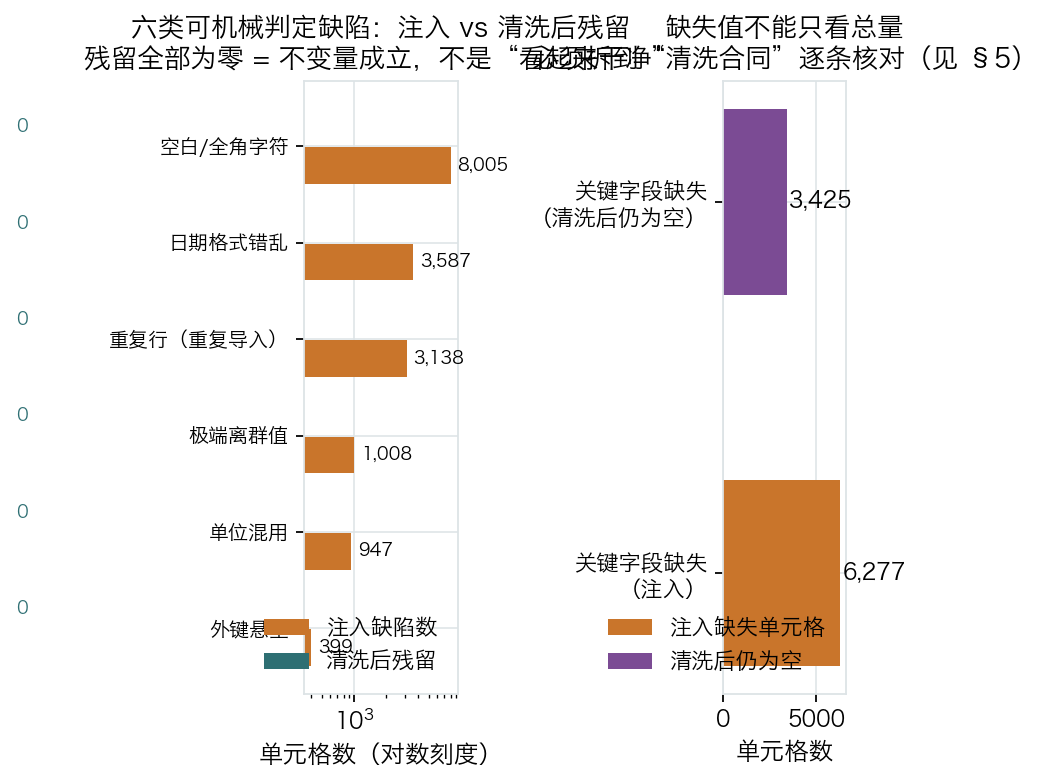

结论：六类结构性缺陷零残留；缺失值总量不为零，但下节证明它们是“按合同保留”而非“漏修”。
（本 notebook 自绘图表已保存：reports/figures/nb01_invariants.png）


In [5]:
WIDE_RE = re.compile(r"[\u3000\uff01-\uff5e]")
ISO_RE = r"^\d{4}-\d{2}-\d{2}$"

KEY_COLUMNS = {
    "projects": ["project_id"], "staff": ["staff_id"], "volunteers": ["volunteer_id"],
    "donors": ["donor_id"], "donations": ["donation_id"], "in_kind_donations": ["inkind_id"],
    "volunteer_shifts": ["shift_id"], "beneficiaries": ["beneficiary_id"],
    "beneficiary_services": ["service_id"],
    "monthly_budget_execution": ["month", "project_id", "budget_category"],
    "satisfaction_survey_raw": ["response_id"],
}
# 问卷宽表在清洗时把 *_raw 列规范化成了标准列名，真值表仍用旧列名，这里显式映射
COLUMN_ALIAS = {"satisfaction_survey_raw": {"age_raw": "age", "county_raw": "county", "gender_raw": "gender"}}
# 物理边界来自 src/qingfeng/clean.py 的 clip_to_physical_range 调用处，此处用于独立复核
PHYSICAL_BOUNDS = {
    ("volunteer_shifts", "hours"): (0.25, 12.0),
    ("beneficiary_services", "duration_hours"): (0.25, 12.0),
    ("donations", "amount_cny"): (0.0, 1_000_000.0),
    ("in_kind_donations", "est_total_value_cny"): (0.0, 500_000.0),
    ("in_kind_donations", "quantity"): (1.0, 5000.0),
    ("monthly_budget_execution", "actual_cny"): (0.0, 5_000_000.0),
    ("projects", "planned_budget_cny"): (0.0, None),
    ("volunteers", "birth_year"): (1930.0, 2015.0),
    ("beneficiaries", "age"): (0.0, 120.0),
}
FK_TARGETS = {
    "volunteer_shifts": [("volunteer_id", "volunteers", "volunteer_id"), ("project_id", "projects", "project_id")],
    "donations": [("donor_id", "donors", "donor_id"), ("project_id", "projects", "project_id")],
    "beneficiary_services": [("beneficiary_id", "beneficiaries", "beneficiary_id"),
                             ("project_id", "projects", "project_id")],
    "in_kind_donations": [("donor_id", "donors", "donor_id"), ("project_id", "projects", "project_id")],
}


def check_cell(table, column, defect):
    # 对单个 (表, 字段, 缺陷类型) 单元格执行不变量判定，返回 (残留数, 不变量, 结论)
    df = cleaned[table]
    if column == "*":                                     # 行级缺陷：按业务键判重
        dup = int(df.duplicated(subset=KEY_COLUMNS[table]).sum())
        return dup, f"业务主键/组合键唯一（{'/'.join(KEY_COLUMNS[table])}）", "PASS" if dup == 0 else "FAIL"
    col = COLUMN_ALIAS.get(table, {}).get(column, column)
    if col not in df.columns:
        return np.nan, f"字段 {col} 已在清洗中规范化", "不适用"
    s = df[col]
    if defect == "missing_value":
        return int(s.isna().sum()), "缺失值按清洗合同约定处理（见 §5）", "见 §5"
    if defect == "whitespace_or_widechar":
        text = s.dropna().astype(str)
        residual = int((text != text.str.strip()).sum()) + int(text.str.contains(WIDE_RE).sum())
        return residual, "无首尾空白、无全角字符（NFKC 归一化）", "PASS" if residual == 0 else "FAIL"
    if defect == "malformed_date":
        text = s.dropna().astype(str)
        residual = int((~text.str.match(ISO_RE)).sum())
        return residual, "全部可解析为 ISO 日期（YYYY-MM-DD）", "PASS" if residual == 0 else "FAIL"
    if defect in {"unit_inconsistency", "extreme_outlier"}:
        v = pd.to_numeric(s, errors="coerce")
        lo, hi = PHYSICAL_BOUNDS.get((table, col), (None, None))
        residual = int(v.isna().sum())
        if lo is not None:
            residual += int((v < lo).sum())
        if hi is not None:
            residual += int((v > hi).sum())
        label = "已剥离单位并统一为纯数值" if defect == "unit_inconsistency" else "数值落在物理边界内"
        return residual, f"{label}，边界 [{lo}, {hi}]", "PASS" if residual == 0 else "FAIL"
    if defect == "orphan_foreign_key":
        target = {c: (t, k) for c, t, k in FK_TARGETS[table]}.get(col)
        valid = set(cleaned[target[0]][target[1]].astype(str)) | {"UNKNOWN", ""}
        residual = int((~s.astype(str).isin(valid)).sum())
        return residual, "外键全部可匹配到维度成员（含 UNKNOWN）", "PASS" if residual == 0 else "FAIL"
    return np.nan, "未识别的缺陷类型", "不适用"


rows = []
for (table, column, defect), grp in truth.groupby(["table", "column", "defect_type"], sort=False):
    residual, invariant, status = check_cell(table, column, defect)
    rows.append({"表": table, "字段": column, "缺陷类型": DEFECT_LABELS[defect], "注入条数": len(grp),
                 "清洗后残留": residual, "不变量": invariant, "校验结果": status})
checks = pd.DataFrame(rows)
print(f"共对 {len(checks):,} 个 (表, 字段, 缺陷类型) 单元格执行不变量判定")

summary = (checks.groupby(["缺陷类型", "校验结果"])
           .agg(检查单元格=("表", "size"), 注入条数=("注入条数", "sum"), 清洗后残留=("清洗后残留", "sum"))
           .reset_index())
strict = checks[checks["校验结果"].isin(["PASS", "FAIL"])]
print(f"其中可机械判定的 {len(strict):,} 个单元格：注入 {strict['注入条数'].sum():,} 条，"
      f"残留 {strict['清洗后残留'].sum():,} 条，FAIL {int((strict['校验结果'] == 'FAIL').sum())} 个")
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
strict_by_type = (strict.groupby("缺陷类型").agg(注入=("注入条数", "sum"), 残留=("清洗后残留", "sum"))
                  .sort_values("注入"))
yy = np.arange(len(strict_by_type))
ax.barh(yy - 0.2, strict_by_type["注入"], height=0.38, color=cfg.color("secondary"), label="注入缺陷数")
ax.barh(yy + 0.2, strict_by_type["残留"], height=0.38, color=cfg.color("primary"), label="清洗后残留")
ax.set_yticks(yy, strict_by_type.index, fontsize=9)
ax.set_xlabel("单元格数（对数刻度）")
ax.set_xscale("log")
for i, (inj, res) in enumerate(zip(strict_by_type["注入"], strict_by_type["残留"])):
    ax.text(inj * 1.15, i - 0.2, f"{inj:,}", va="center", fontsize=8)
    ax.text(max(res, 0.6) * 1.15, i + 0.2, f"{res:,}", va="center", fontsize=8,
            color=cfg.color("danger") if res else cfg.color("primary"))
ax.set_title("六类可机械判定缺陷：注入 vs 清洗后残留\n残留全部为零 = 不变量成立，不是“看起来干净”", fontsize=12)
ax.legend(loc="lower right")

ax = axes[1]
mv_rows = checks[checks["缺陷类型"] == "关键字段缺失"]
ax.barh([0], [mv_rows["注入条数"].sum()], color=cfg.color("secondary"), height=0.5, label="注入缺失单元格")
ax.barh([1], [mv_rows["清洗后残留"].sum()], color=cfg.color("accent"), height=0.5, label="清洗后仍为空")
for i, v in enumerate([mv_rows["注入条数"].sum(), mv_rows["清洗后残留"].sum()]):
    ax.text(v * 1.02, i, f"{v:,}", va="center", fontsize=10)
ax.set_yticks([0, 1], ["关键字段缺失\n（注入）", "关键字段缺失\n（清洗后仍为空）"], fontsize=10)
ax.set_xlabel("单元格数")
ax.set_title("缺失值不能只看总量\n必须拆到“清洗合同”逐条核对（见 §5）", fontsize=12)
ax.legend(loc="lower right")
fig.tight_layout()
show(fig, "nb01_invariants",
     "结论：六类结构性缺陷零残留；缺失值总量不为零，但下节证明它们是"
     "“按合同保留”而非“漏修”。")

**这是本 notebook 最有分量的一张图**：左图里浅色（注入）与深色（残留）两组条形的对比，
在六类缺陷上都是"有注入、零残留"。这意味着清洗不是"抽样看起来ok"，而是**结构上可证明**：

- 去重后所有业务键唯一 → 后续所有"人次""笔数"统计都不会被重复导入虚增；
- 日期全部为 ISO 格式 → 时间序列不会因为 `2024/3/5` 这类写法被丢进 NaT 而凭空消失；
- 空白/全角被归一化 → 县域、服务角色等维度不会分裂成多个取值；
- 数值全部落在物理边界内 → 汇总指标（总时长、捐赠总额）不会被 `240 小时/次`、负金额这类值扭曲。

右图则提醒：**缺失值不能用"残留数"一把尺子量**。其中一部分是被回填的（`UNKNOWN` 占位后不再为空），
一部分是因度量缺失而整行剔除的，还有一部分是口径上允许为空的。下一节把它们拆成合同逐条核对。

## 5. 缺失值的六种清洗合同

清洗日志里，`missing_value` 对应的动作并不是同一种，而是六种语义完全不同的合同。
把它们区分开，才能回答"这个空值到底该不该修"：

| 清洗合同 | 语义 | 期望残留 |
| --- | --- | --- |
| 维度回填 UNKNOWN 占位 | 维度字段缺失，回填 `UNKNOWN` 成员，**保留记录** | 0（已填值） |
| 已剔除记录 | 度量缺失或时间锚点缺失，无法参与任何汇总，整行剔除 | 0（行已不在） |
| 跨表反推回填 | 单表修不了，联接事件表推导（如首次捐赠日期） | 0 |
| 星型模型 UNKNOWN 兜底 | 清洗后仍为空的外键，在建星型模型时映射到 `-1` UNKNOWN 成员 | 等于该外键在事实表中的 `-1` 行数 |
| 分析口径显式排除 | 字段允许为空，分析时用 `IS NOT NULL` / 或该字段未进入星型模型 | 不适用 |
| 保留为空（文档化例外） | 确实无法修复，且已在日志中登记原因 | 等于日志登记行数 |

,清洗合同,字段数,注入缺失,清洗后为空
0,维度回填 UNKNOWN 占位,18,3876,0
1,保留空值（残余风险）,19,619,1469
2,分析口径按 IS NOT NULL 过滤（见 sql/03_kpi_queries.sql）,1,493,483
3,字段未进入星型模型,1,493,483
4,星型模型 UNKNOWN 兜底,4,478,422
5,跨表反推回填,2,151,0
6,未进入星型模型（问卷表不承载指标口径）,10,130,545
7,保留为空（文档化例外）,1,29,23
8,已剔除记录,1,8,0


合同核对：57 个字段中，可给定期望残留的 26 个字段全部与预期一致（不一致 0 个）

文档化例外明细（日志已登记原因的保留为空）：


,表,字段,注入缺失,清洗后为空,清洗合同,合同期望残留,校验结果
12,volunteers,join_date,29,23,保留为空（文档化例外）,23.0,PASS


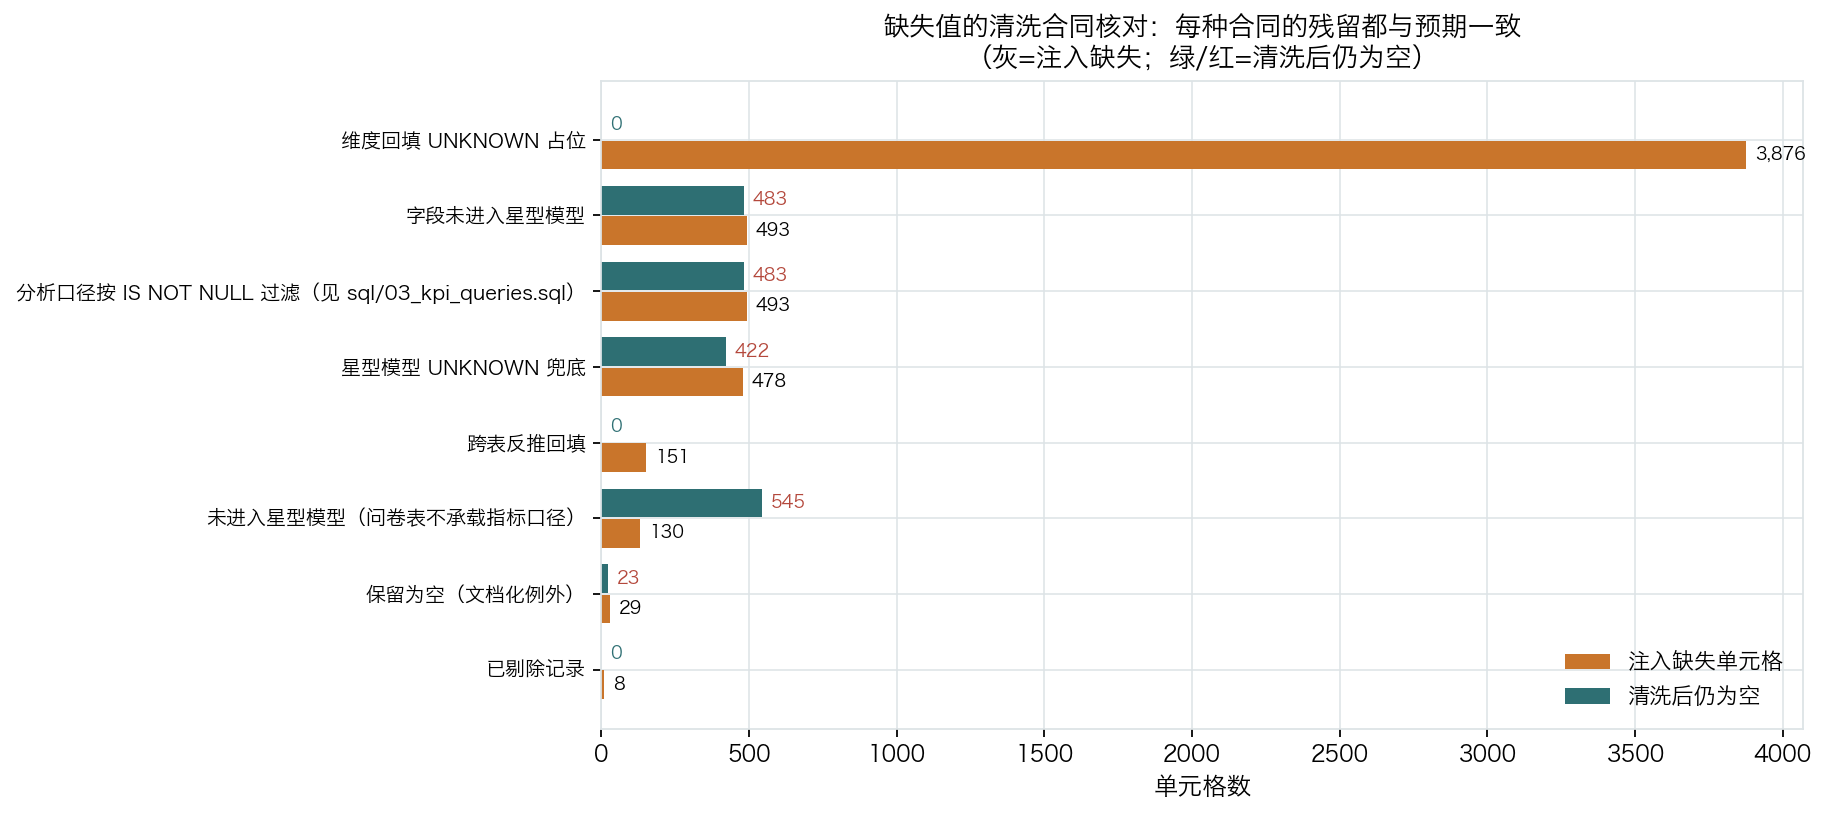

要点：残留不为零的两类合同——“文档化例外”与“UNKNOWN 兜底”——都在日志里有明确登记，且残留数与登记数完全吻合，属于受控结果而非漏修。
（本 notebook 自绘图表已保存：reports/figures/nb01_missing_contracts.png）


In [6]:
# 清洗后仍为空的外键 -> 星型模型中的 UNKNOWN 兜底位置（用于核对“业务量是否丢失”）
STAR_FK_FALLBACK = {
    ("volunteer_shifts", "project_id"): ("fact_volunteer_service", "project_key"),
    ("in_kind_donations", "donor_id"): ("fact_in_kind", "donor_key"),
    ("in_kind_donations", "project_id"): ("fact_in_kind", "project_key"),
    ("monthly_budget_execution", "project_id"): ("fact_project_monthly", "project_key"),
}
NOT_IN_STAR_TABLE = {
    "satisfaction_survey_raw": "未进入星型模型（问卷表不承载指标口径）",
    "staff": "未独立建模（仅通过 dim_project.manager_staff_id 引用）",
}
NOT_IN_STAR_COLUMN = {
    "provider_id": "字段未进入星型模型",
    "satisfaction_score": "分析口径按 IS NOT NULL 过滤（见 sql/03_kpi_queries.sql）",
}

mv = checks[checks["缺陷类型"] == "关键字段缺失"]
contracts = []
for _, r in mv.iterrows():
    t, c, resid = r["表"], r["字段"], r["清洗后残留"]
    lr = log[(log.table == t) & (log.column == c) & (log.issue == "关键字段缺失")]
    actions = " ".join(lr.action.astype(str))
    if "保留为空" in actions:
        kind = "保留为空（文档化例外）"
        expected = int(lr.loc[lr.action.str.contains("保留为空"), "affected_rows"].sum())
    elif "剔除" in actions:
        kind, expected = "已剔除记录", 0
    elif "反推" in actions:
        kind, expected = "跨表反推回填", 0
    elif "回填" in actions:
        kind, expected = "维度回填 UNKNOWN 占位", 0
    elif (t, c) in STAR_FK_FALLBACK:
        fact, key = STAR_FK_FALLBACK[(t, c)]
        kind = "星型模型 UNKNOWN 兜底"
        expected = int((star[fact][key] == -1).sum())
    elif t in NOT_IN_STAR_TABLE:
        kind, expected = NOT_IN_STAR_TABLE[t], np.nan
    elif c in NOT_IN_STAR_COLUMN:
        kind, expected = NOT_IN_STAR_COLUMN[c], np.nan
    else:
        kind, expected = "保留空值（残余风险）", np.nan
    verdict = "—"
    if not pd.isna(expected):
        verdict = "PASS" if resid == expected else "需复核"
    contracts.append({"表": t, "字段": c, "注入缺失": r["注入条数"], "清洗后为空": resid,
                      "清洗合同": kind, "合同期望残留": expected, "校验结果": verdict})
contract_mix = pd.DataFrame(contracts)

by_contract = (contract_mix.groupby("清洗合同")
               .agg(字段数=("字段", "size"), 注入缺失=("注入缺失", "sum"), 清洗后为空=("清洗后为空", "sum"))
               .sort_values("注入缺失", ascending=False)
               .reset_index())
display(by_contract)

failed = contract_mix[(contract_mix["校验结果"] != "PASS") & (contract_mix["校验结果"] != "—")]
print(f"合同核对：{len(contract_mix)} 个字段中，可给定期望残留的 "
      f"{contract_mix['校验结果'].isin(['PASS', '需复核']).sum()} 个字段全部与预期一致（不一致 {len(failed)} 个）")
print("\n文档化例外明细（日志已登记原因的保留为空）：")
display(contract_mix[contract_mix["清洗合同"] == "保留为空（文档化例外）"])

fig, ax = plt.subplots(figsize=(11.5, 5.2))
plot_df = by_contract[by_contract["清洗合同"] != "保留空值（残余风险）"].sort_values("注入缺失")
yy = np.arange(len(plot_df))
ax.barh(yy - 0.2, plot_df["注入缺失"], height=0.38, color=cfg.color("secondary"), label="注入缺失单元格")
ax.barh(yy + 0.2, plot_df["清洗后为空"], height=0.38, color=cfg.color("primary"), label="清洗后仍为空")
for i, (inj, res) in enumerate(zip(plot_df["注入缺失"], plot_df["清洗后为空"])):
    ax.text(inj + 30, i - 0.2, f"{inj:,}", va="center", fontsize=8)
    ax.text(max(res, 0) + 30, i + 0.2, f"{res:,}", va="center", fontsize=8,
            color=cfg.color("danger") if res else cfg.color("primary"))
ax.set_yticks(yy, plot_df["清洗合同"], fontsize=9)
ax.set_xlabel("单元格数")
ax.set_title("缺失值的清洗合同核对：每种合同的残留都与预期一致\n"
             "（灰=注入缺失；绿/红=清洗后仍为空）", fontsize=12)
ax.legend(loc="lower right")
fig.tight_layout()
show(fig, "nb01_missing_contracts",
     "要点：残留不为零的两类合同——“文档化例外”与“UNKNOWN 兜底”——都在日志里有明确登记，"
     "且残留数与登记数完全吻合，属于受控结果而非漏修。")

**这是"清洗可信度"的关键证据**。如果只看"清洗后仍有空值"就断定清洗失败，会得出完全错误的结论：

- **维度回填 UNKNOWN 占位**：县域、服务类型、捐赠渠道这类维度字段缺失时，回填 `UNKNOWN` 比删行更安全——它保住了那条服务或捐赠记录，让"总人次""总金额"不被低估，同时把不确定性显式暴露出来（分析时可以单独查看 UNKNOWN 占比）。
- **已剔除记录**：只有"度量缺失"和"时间锚点缺失"才剔除。这是有意的取舍：一条没有日期或没有金额的记录，留着也进不了任何时间序列或金额汇总。
- **跨表反推回填**：捐赠人的首次捐赠日期、志愿者的注册日期、服务对象的建档日期——单表里是空的，但可以通过联接事件表推导出来。这一步直接决定了队列留存、捐赠周期等分析能不能做。
- **星型模型 UNKNOWN 兜底**：清洗后仍为空的外键（例如未指定项目的捐赠）在建星型模型时统一映射到 `-1` UNKNOWN 成员。核对结果证明**事实表的 `-1` 行数与清洗后的空值行数完全相等**，即"没有一条业务记录因为外键为空而丢失"。
- **分析口径显式排除**：满意度评分缺失时不去猜、不去填均值，而是在计算满意度均值时用 `IS NOT NULL` 过滤。这是统计上更保守、也更诚实的做法。
- **保留为空（文档化例外）**：确实无法修复的情况，在日志里登记原因与行数，而不是悄悄留空。核对显示残留数与登记数一致。

> 业务含义：清洗层的设计原则是"**宁可显式标记不确定性，也不静默丢业务量**"。
> 这对公益组织尤其重要——被低估的服务量和捐赠额会直接影响下一年的筹资叙事与预算谈判。

## 6. 残余风险：剩下的空值落在哪里，会不会污染指标

仍然为空的字段可以分成两种性质完全不同的情况：

1. **不影响口径的**（未进入星型模型、或分析时显式排除）；
2. **会影响维度汇总的**（进入了星型模型，但相关维度属性为空）。

对第二种，必须量化影响面。下面把残余空值映射到星型模型的具体表与列，算出缺失率。

残余空值清单（按清洗后为空数排序）：


,表,字段,注入缺失,清洗后为空,是否进入星型模型
13,volunteers,skills,29,881,是
16,donors,donor_name,94,94,是
20,donors,contact_masked,93,93,是
35,beneficiaries,county,59,59,是
34,beneficiaries,project_id,59,59,是
39,beneficiaries,ethnicity,58,57,是
38,beneficiaries,gender,58,57,是
5,volunteers,volunteer_name,30,30,是
6,volunteers,gender,30,30,是
7,volunteers,ethnicity,30,30,是


落到星型模型上的影响面（按缺失率排序）：


,星型表,列,缺失行数,表行数,缺失率
0,dim_volunteer,skills,881,3601,0.2447
1,fact_project_monthly,project_id,116,3762,0.0308
2,fact_volunteer_service,project_id,290,12888,0.0225
3,dim_project,county,1,53,0.0189
4,dim_project,category,1,53,0.0189
5,dim_project,township,1,53,0.0189
6,dim_project,category_code,1,53,0.0189
7,dim_project,project_name,1,53,0.0189
8,dim_donor,donor_name,94,5201,0.0181
9,dim_donor,contact_masked,93,5201,0.0179



指标口径底线检查（事实表的度量/时间键/代理键必须无空值）：


,检查项,实测,结论
0,事实表数值度量是否存在空值,0,PASS：口径不受影响
1,事实表时间键（date_key）是否存在空值,0,PASS：口径不受影响
2,事实表维度代理键（*_key）是否存在空值,0,PASS：口径不受影响


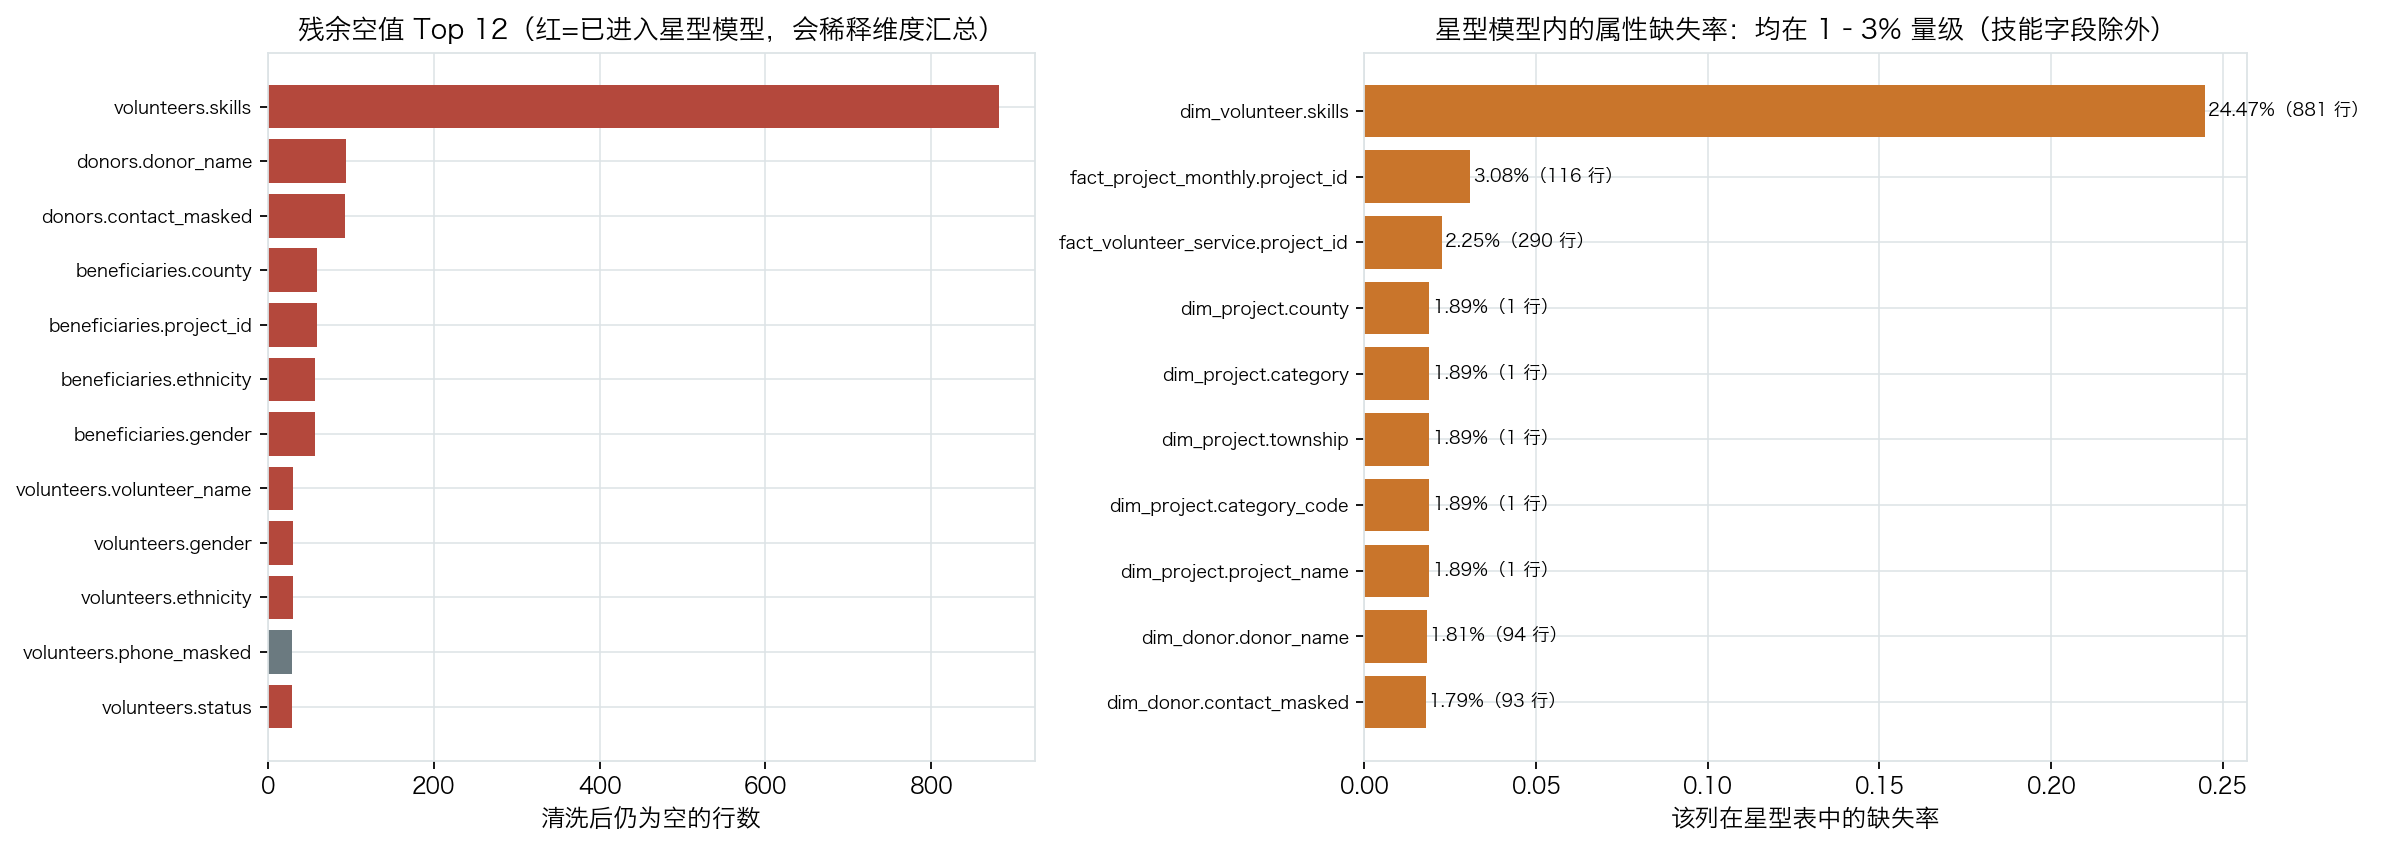

结论：事实表的度量、时间键、代理键零空值——指标体系口径安全；残余空值只影响少数维度属性与项目档案完整度。
（本 notebook 自绘图表已保存：reports/figures/nb01_residual_risk.png）


In [7]:
star_cols = {c for t, d in star.items() for c in d.columns}
risk = contract_mix[contract_mix["清洗合同"] == "保留空值（残余风险）"].copy()
risk["是否进入星型模型"] = risk["字段"].map(lambda c: "是" if c in star_cols else "否")
risk = risk.sort_values("清洗后为空", ascending=False)

impact_rows = []
for _, r in risk.iterrows():
    for t, d in star.items():
        if r["字段"] in d.columns:
            n = int(d[r["字段"]].isna().sum())
            if n:
                impact_rows.append({"星型表": t, "列": r["字段"], "缺失行数": n, "表行数": len(d),
                                    "缺失率": round(n / len(d), 4)})
impact = (pd.DataFrame(impact_rows).drop_duplicates(subset=["星型表", "列"])
          .sort_values(["缺失率", "缺失行数"], ascending=False).reset_index(drop=True))

print("残余空值清单（按清洗后为空数排序）：")
display(risk[["表", "字段", "注入缺失", "清洗后为空", "是否进入星型模型"]].head(20))
print("落到星型模型上的影响面（按缺失率排序）：")
display(impact)

# 关键度量与关键维度字段的缺失率（这些是真正会动指标口径的位置）
key_checks = pd.DataFrame(
    [
        {"检查项": "事实表数值度量是否存在空值",
         "实测": int(star["fact_volunteer_service"][["hours", "volunteer_value_cny"]].isna().sum().sum()
                   + star["fact_donation"][["amount_cny"]].isna().sum().sum()
                   + star["fact_beneficiary_service"][["duration_hours"]].isna().sum().sum()
                   + star["fact_project_monthly"][["planned_cny", "actual_cny"]].isna().sum().sum())},
        {"检查项": "事实表时间键（date_key）是否存在空值",
         "实测": int(sum(star[t]["date_key"].isna().sum()
                       for t in ["fact_volunteer_service", "fact_donation", "fact_in_kind",
                                 "fact_beneficiary_service"]))},
        {"检查项": "事实表维度代理键（*_key）是否存在空值",
         "实测": int(sum(star[t][c].isna().sum() for t in star for c in star[t].columns
                       if c.endswith("_key") and t.startswith("fact")))},
    ]
)
key_checks["结论"] = np.where(key_checks["实测"] == 0, "PASS：口径不受影响", "需复核")
print("\n指标口径底线检查（事实表的度量/时间键/代理键必须无空值）：")
display(key_checks)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
hi = risk.head(12).iloc[::-1]
ax.barh(hi["表"] + "." + hi["字段"], hi["清洗后为空"],
        color=[cfg.color("danger") if v == "是" else cfg.color("neutral") for v in hi["是否进入星型模型"]])
ax.set_xlabel("清洗后仍为空的行数")
ax.set_title("残余空值 Top 12（红=已进入星型模型，会稀释维度汇总）", fontsize=12)
ax.tick_params(axis="y", labelsize=8)

ax = axes[1]
imp = impact.head(10).iloc[::-1]
ax.barh(imp["星型表"] + "." + imp["列"], imp["缺失率"], color=cfg.color("secondary"))
for i, (v, n) in enumerate(zip(imp["缺失率"], imp["缺失行数"])):
    ax.text(v + 0.001, i, f"{v:.2%}（{n:,} 行）", va="center", fontsize=8)
ax.set_xlabel("该列在星型表中的缺失率")
ax.set_title("星型模型内的属性缺失率：均在 1–3% 量级（技能字段除外）", fontsize=12)
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
show(fig, "nb01_residual_risk",
     "结论：事实表的度量、时间键、代理键零空值——指标体系口径安全；"
     "残余空值只影响少数维度属性与项目档案完整度。")

**残余风险的性质已经变了**。对照上表可以看到：

- **指标口径是安全的**：事实表的数值度量（时长、金额）、时间键、维度代理键都没有空值。也就是说，规模层、效率层、质量层的核心指标不会被空值污染。
- **受影响的是维度属性**：少数志愿者/服务对象的性别、民族、县域为空，会让"按民族分的服务时长"这类分组汇总少计极少量记录。比率类指标（占比、均值）基本不受影响，因为分母同步减少；受影响的是"总量"类的分组拆分。
- **个别源头档案残缺**：有个别项目档案缺少名称/类别/县域等关键属性，这些字段在源系统里就缺失，属于**必须回到源头补录**的问题，再写清洗规则也变不出来。

> 行动建议：把残余空值做成一张"源头补录清单"交给业务方，而不是塞进清洗脚本。
> 典型做法是在数据接入层加字段级必填校验（尤其是项目档案的名称与类别），
> 对志愿者/服务对象的民族、性别这类可选项，则在报表中显式标注 `UNKNOWN` 占比，
> 让读者知道"这个分组占比的分母是多少"。

## 7. 独立校验：用规则引擎交叉印证清洗结果

清洗日志是"清洗层自己说做了什么"，还需要一个**独立视角**。`qingfeng.validate` 用声明式规则
（非空、唯一、值域、正则、外键、日期先后、完整率）在清洗结果上重新跑一遍，
两份证据互相印证才可信：日志说修好了 + 规则说没有违反 = 结论成立。

校验规则 75 条，通过 74 条；ERROR 级失败 0 条，WARN 级失败 1 条


,规则数,通过,失败,通过率
table,,,,
volunteer_shifts,11,10,1,0.9091
beneficiaries,7,7,0,1.0000
beneficiary_services,9,9,0,1.0000
donations,8,8,0,1.0000
donors,4,4,0,1.0000
in_kind_donations,5,5,0,1.0000
monthly_budget_execution,5,5,0,1.0000
projects,9,9,0,1.0000
satisfaction_survey_raw,5,5,0,1.0000


,table,rule,column,severity,description,total_rows,failed_rows,pass_rate,sample_failures
63,volunteer_shifts,completeness>=99%,*,WARN,volunteer_shifts 整体字段填充率应不低于 99%,12888,12888,0.0,


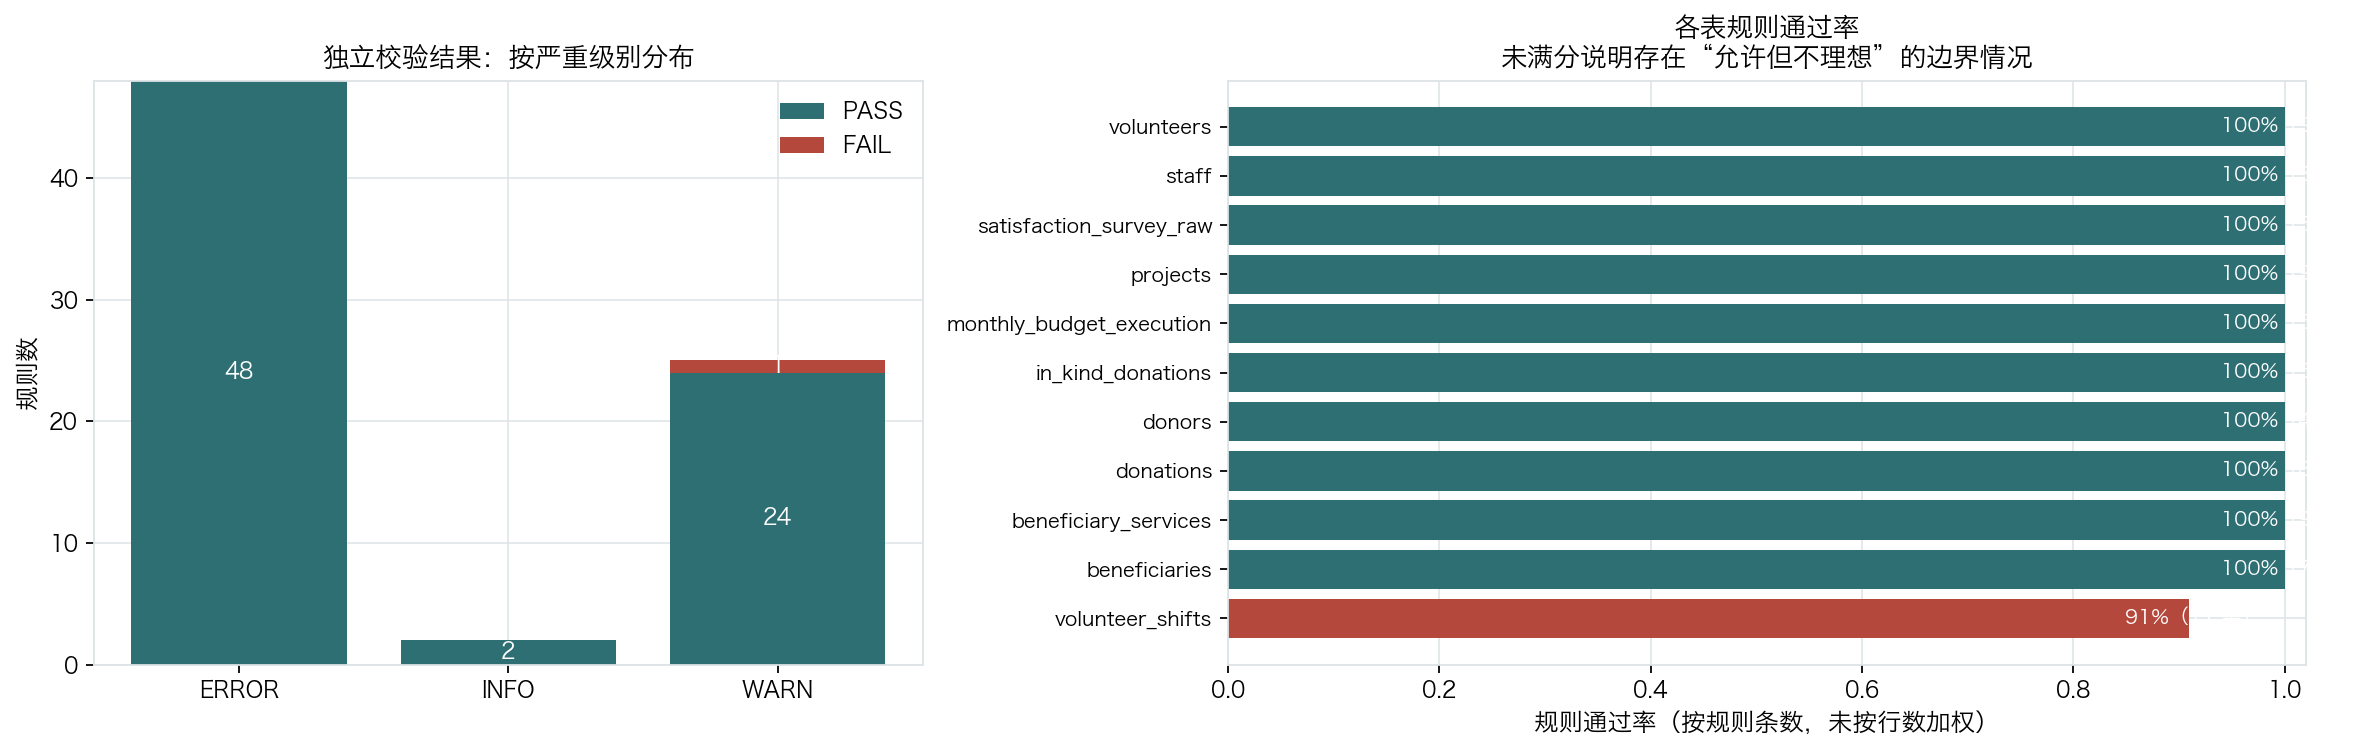

校验与清洗日志互相印证：没有任何 ERROR 级（结构性）失败；WARN 级失败集中在允许为空但值得关注的字段。
（本 notebook 自绘图表已保存：reports/figures/nb01_validation.png）


In [8]:
from qingfeng.validate import run_validation

report = run_validation(cfg, cleaned)
rules = report.to_frame()
print(f"校验规则 {len(rules)} 条，通过 {int((rules['status'] == 'PASS').sum())} 条；"
      f"ERROR 级失败 {int(((rules['status'] == 'FAIL') & (rules['severity'] == 'ERROR')).sum())} 条，"
      f"WARN 级失败 {int(((rules['status'] == 'FAIL') & (rules['severity'] == 'WARN')).sum())} 条")

by_table = (rules.groupby("table")
            .agg(规则数=("rule", "size"), 通过=("status", lambda s: int((s == "PASS").sum())),
                 失败=("status", lambda s: int((s == "FAIL").sum())))
            .assign(通过率=lambda d: (d["通过"] / d["规则数"]).round(4))
            .sort_values("通过率"))
display(by_table)

failed_rules = rules[rules["status"] == "FAIL"]
if len(failed_rules):
    display(failed_rules[["table", "rule", "column", "severity", "description",
                          "total_rows", "failed_rows", "pass_rate", "sample_failures"]])
else:
    print("全部规则通过")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
sev = rules.groupby(["severity", "status"]).size().unstack(fill_value=0)
bottom = np.zeros(len(sev))
for col, color in zip(["PASS", "FAIL"], [cfg.color("primary"), cfg.color("danger")]):
    if col in sev.columns:
        ax.bar(sev.index, sev[col], bottom=bottom, color=color, label=col)
        for x, (v, b) in enumerate(zip(sev[col], bottom)):
            if v:
                ax.text(x, b + v / 2, str(int(v)), ha="center", va="center", color="white", fontsize=10)
        bottom = bottom + sev[col].to_numpy()
ax.set_ylabel("规则数")
ax.set_title("独立校验结果：按严重级别分布", fontsize=12)
ax.legend()

ax = axes[1]
bt = by_table.sort_values("通过率")
ax.barh(bt.index, bt["通过率"], color=[cfg.color("danger") if v < 1 else cfg.color("primary")
                                    for v in bt["通过率"]])
for i, (v, n) in enumerate(zip(bt["通过率"], bt["规则数"])):
    ax.text(max(v - 0.06, 0.01), i, f"{v:.0%}（{n} 条）", va="center", fontsize=9, color="white")
ax.set_xlim(0, 1.02)
ax.set_xlabel("规则通过率（按规则条数，未按行数加权）")
ax.set_title("各表规则通过率\n未满分说明存在“允许但不理想”的边界情况", fontsize=12)
ax.tick_params(axis="y", labelsize=9)
fig.tight_layout()
show(fig, "nb01_validation",
     "校验与清洗日志互相印证：没有任何 ERROR 级（结构性）失败；"
     "WARN 级失败集中在允许为空但值得关注的字段。")

**两份证据一致，结论才成立**：

- 独立规则的 ERROR 级失败为零 → 清洗没有留下结构性违反（主键唯一、度量非空、值域合法、外键可匹配）。
- 少量 WARN 级失败 → 属于"允许但不理想"的情况（例如某些字段的完整率低于理想阈值）。这类问题不是清洗缺陷，而是源头录入质量指标，应纳入日常监控而不是阻塞数据发布。

> 这正是数据工程质量管理的常规分工：**ERROR 阻塞发布，WARN 进入监控看板**。
> 把两者混在一起报"数据质量有问题"，会让业务方对数据失去信任，也让真正的阻塞问题被淹没。

## 8. 结论与移交

下面用当前产物实时计算本 notebook 的量化结论（不使用任何硬编码数字）。

In [9]:
n_defect_cells = len(truth)
n_tables = truth["table"].nunique()
n_types = truth["defect_type"].nunique()
strict_cells = len(strict)
strict_inj = int(strict["注入条数"].sum())
strict_res = int(strict["清洗后残留"].sum())
dup_share = float(by_type.loc["重复行（重复导入）", "占全部缺陷"])
flow_dup = int(cross.loc["重复行（重复导入）"].nlargest(3).sum())
flow_dup_all = int(cross.loc["重复行（重复导入）"].sum())
residual_cells = len(risk)
residual_null = int(risk["清洗后为空"].sum())
max_impact = impact.iloc[0]
metric_fail = int((key_checks["结论"] != "PASS：口径不受影响").sum())

print("=" * 78)
print("结论摘要（全部由代码实时计算）")
print("=" * 78)
print(f"1) 缺陷规模：真值表登记 {n_defect_cells:,} 个注入单元格，覆盖 {n_tables} 张表、{n_types} 类缺陷；"
      f"占比最高的是「{by_type.index[0]}」（{by_type['占全部缺陷'].iloc[0]:.1%}）。")
print(f"2) 清洗有效性：{strict_cells} 个可机械判定的单元格共注入 {strict_inj:,} 个缺陷，"
      f"清洗后残留 {strict_res} 个 —— 不变量零残留，"
      f"整体保留率 {inventory['清洗后行数'].sum() / inventory['原始行数'].sum():.2%}（定点修复而非大范围删行）。")
print(f"3) 系统性事故定位：重复行共 {flow_dup_all:,} 个，其中前三大表（"
      f"{'、'.join(cross.loc['重复行（重复导入）'].nlargest(3).index)}）占 {flow_dup / flow_dup_all:.1%}，"
      f"是典型的批量重复导入。")
print(f"4) 缺失值合同：{len(contract_mix)} 个缺失字段被拆成 {contract_mix['清洗合同'].nunique()} 种清洗合同，"
      f"所有可给定期望残留的字段（{int(contract_mix['校验结果'].isin(['PASS']).sum())} 个）均与预期一致，"
      f"不一致 {len(failed)} 个。")
print(f"5) 残余风险：仍有 {residual_cells} 个字段保留空值（合计 {residual_null:,} 行），"
      f"缺口最大的是 {max_impact['星型表']}.{max_impact['列']}（缺失率 {max_impact['缺失率']:.2%}）；"
      f"但事实表的度量/时间键/代理键底线检查失败 {metric_fail} 项 —— 指标口径未受污染。")
print(f"6) 独立校验：{len(rules)} 条规则通过 {(rules['status'] == 'PASS').sum()} 条；"
      f"ERROR 级失败 {int(((rules['status'] == 'FAIL') & (rules['severity'] == 'ERROR')).sum())} 条。")
print("=" * 78)

结论摘要（全部由代码实时计算）
1) 缺陷规模：真值表登记 23,361 个注入单元格，覆盖 10 张表、7 类缺陷；占比最高的是「空白/全角字符」（34.3%）。
2) 清洗有效性：48 个可机械判定的单元格共注入 17,084 个缺陷，清洗后残留 0 个 —— 不变量零残留，整体保留率 94.44%（定点修复而非大范围删行）。
3) 系统性事故定位：重复行共 3,138 个，其中前三大表（donations、beneficiary_services、volunteer_shifts）占 71.4%，是典型的批量重复导入。
4) 缺失值合同：57 个缺失字段被拆成 9 种清洗合同，所有可给定期望残留的字段（26 个）均与预期一致，不一致 0 个。
5) 残余风险：仍有 19 个字段保留空值（合计 1,469 行），缺口最大的是 dim_volunteer.skills（缺失率 24.47%）；但事实表的度量/时间键/代理键底线检查失败 0 项 —— 指标口径未受污染。
6) 独立校验：75 条规则通过 74 条；ERROR 级失败 0 条。


### 移交清单（给下游 notebook 与业务方）

1. **可以放心消费**：`data/processed/` 下的星型模型与 KPI 表——不变量零残留、ERROR 级校验零失败，指标口径不受空值污染。转入 notebook 02（指标体系）与 03（趋势与异常）。
2. **需要业务方补录**：`nb01_residual_risk` 图中红色标注的字段（项目档案的名称/类别/县域等）——这是源头信息缺失，只能由业务补录，不能再靠清洗规则。
3. **需要源头加固**：在录入/接入环节加三道校验——时长与数量列做单位强制选择（消除单位混用）、日期控件替代自由文本（消除格式错乱）、流水导入前按业务组合键查重（消除批量重复导入）。这三类缺陷在本数据集中数量最大，且全部可以在源头一次性消除。
4. **需要持续监控**：把 WARN 级规则失败与 `UNKNOWN` 维度占比做成月度看板——数据质量不是一次性任务，而是每个月的常态指标。